# Objective 2 - Linear Regression
- **LR 2.1:** predicting the goal difference of each match (104 rows)
- **LR 2.2:** predicting the goals scored by a team in a match (208 rows)

## Part 1 - Data preparation

In [6]:
import random
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PERMA_SEED = 42
random.seed(PERMA_SEED)
np.random.seed(PERMA_SEED)

# connect to the database and load the tables we need
conn = sqlite3.connect("../db/fifa2026.db")

matches = pd.read_sql("SELECT * FROM matches", conn)
teams = pd.read_sql("SELECT * FROM teams", conn)
squads = pd.read_sql("SELECT * FROM squads_and_players", conn)
venues = pd.read_sql("SELECT * FROM venues", conn)
stages = pd.read_sql("SELECT * FROM tournament_stages", conn)

print(matches.shape, teams.shape, squads.shape, venues.shape, stages.shape)

(104, 17) (48, 8) (1248, 10) (16, 8) (7, 3)


In [7]:
# age of each player on the opening day (11 June 2026)
squads["age"] = (pd.to_datetime("2026-06-11") - pd.to_datetime(squads["date_of_birth"])).dt.days / 365.25

# one row per team
team_info = squads.groupby("team_id").agg(
    squad_value=("market_value_eur", "sum"),
    avg_age=("age", "mean"),
    total_caps=("caps", "sum"),
    avg_height=("height_cm", "mean"),
).reset_index()

# international goals scored by each team's forwards
fwd_goals = squads[squads["position"] == "FWD"].groupby("team_id")["goals"].sum().reset_index(name="fwd_goals")

team_info = team_info.merge(fwd_goals, on="team_id")
team_info = team_info.merge(teams[["team_id", "team_name", "fifa_code", "elo_rating"]], on="team_id")

print(team_info.shape)
team_info.sort_values("squad_value", ascending=False).head()

(48, 9)


,team_id,squad_value,avg_age,total_caps,avg_height,fwd_goals,team_name,fifa_code,elo_rating
28,29,2134173029,26.747433,758,181.730769,78,Spain,ESP,2120
32,33,1546204469,27.001000,816,184.923077,83,France,FRA,2100
44,45,1321818896,27.273206,853,184.615385,126,England,ENG,2050
40,41,1145908765,28.035276,1176,181.500000,188,Portugal,POR,2010
36,37,1025039444,29.118201,1267,179.576923,179,Argentina,ARG,2150


In [8]:
# add stage (group / knockout) and venue details to each match
matches = matches.merge(stages[["stage_id", "is_knockout"]], on="stage_id")
matches = matches.merge(venues[["venue_id", "country", "elevation_meters"]], on="venue_id")
matches["kickoff"] = pd.to_datetime(matches["date"] + " " + matches["kickoff_time_utc"])

# each match has two teams, so make one row for each team's side of the game
home = pd.DataFrame({
    "match_id": matches["match_id"], "kickoff": matches["kickoff"],
    "team_id": matches["home_team_id"], "opp_id": matches["away_team_id"],
    "goals_for": matches["home_score"], "goals_against": matches["away_score"],
    "xg_for": matches["home_xg"], "xg_against": matches["away_xg"],
    "is_home": 1, "is_knockout": matches["is_knockout"],
    "venue_country": matches["country"], "elevation": matches["elevation_meters"],
})
away = pd.DataFrame({
    "match_id": matches["match_id"], "kickoff": matches["kickoff"],
    "team_id": matches["away_team_id"], "opp_id": matches["home_team_id"],
    "goals_for": matches["away_score"], "goals_against": matches["home_score"],
    "xg_for": matches["away_xg"], "xg_against": matches["home_xg"],
    "is_home": 0, "is_knockout": matches["is_knockout"],
    "venue_country": matches["country"], "elevation": matches["elevation_meters"],
})

team_matches = pd.concat([home, away]).sort_values(["team_id", "kickoff"]).reset_index(drop=True)
print(team_matches.shape)

(208, 12)


### Form from earlier matches only
For each match we use the team's average xG from its **previous** matches: (total xG so far − this match's xG) ÷ number of earlier matches.
A team's first match has no history, so it gets a neutral value of 1.3. Rest days for the first match are set to 7.

In [9]:
by_team = team_matches.groupby("team_id")
games_before = by_team.cumcount()

# average xG from earlier matches only (this match is subtracted out)
team_matches["prev_xg_for"] = (by_team["xg_for"].cumsum() - team_matches["xg_for"]) / games_before
team_matches["prev_xg_against"] = (by_team["xg_against"].cumsum() - team_matches["xg_against"]) / games_before
team_matches["rest_days"] = by_team["kickoff"].diff().dt.days

# first match of each team: no history yet
team_matches["prev_xg_for"] = team_matches["prev_xg_for"].fillna(1.3)
team_matches["prev_xg_against"] = team_matches["prev_xg_against"].fillna(1.3)
team_matches["rest_days"] = team_matches["rest_days"].fillna(7)

# add squad stats, and mark host nations playing in their own country
team_matches = team_matches.merge(team_info, on="team_id")
team_matches["is_host"] = (team_matches["fifa_code"] == team_matches["venue_country"]).astype(int)

team_matches[["team_name", "match_id", "xg_for", "prev_xg_for", "rest_days", "is_host"]].head(6)

,team_name,match_id,xg_for,prev_xg_for,rest_days,is_host
0,Mexico,1,1.84,1.300000,7.0,1
1,Mexico,25,1.62,1.840000,6.0,1
2,Mexico,49,1.27,1.730000,6.0,1
3,Mexico,79,1.02,1.576667,6.0,1
4,Mexico,92,1.88,1.437500,4.0,1
5,South Africa,1,0.52,1.300000,7.0,0


## Part 2 - LR 2.1: Predicting goal difference
One row per match (104 rows). Target = home goals − away goals.

Each feature compares the two teams (Team A − Team B), except `is_knockout`.

| SN | Column name | What it does | Why does this matter | Known before kickoff? |
| -- | -- | -- | -- | -- |
| 1 | Elo rating difference | Team A strength - Team B Strength, higher = stronger, before tourney ratings | Stronger team win often, and with more goals | Yes, pre-tourney ratings |
| 2 | Squad age difference | How older is Team A's squad compared to Team B on average? | Experience vs energy - do older squads perform better, or do younger blood prevail? | Yes - DOB to kickoff day math |
| 3 | Caps difference | Team A's international appearance vs Team B's (difference) | Do big-match experience matter here? | Yes, pre-WC caps count |
| 4 | Goal difference | Total international career goals by the entire squad, combined (Team A - Team B) | How good is the attack for each team? | Yes, from squad pre-WC |
| 5 | Rest days difference | Days since each team played the last game (Team A - Team B, the usual). First match is counted as 10 days of difference | Tired players probably don't perform as well | Yes, schedule is published before world cup |
| 6 | Is knockout? | 1 if knockout, 0 if not | Higher stakes - do teams perform better under pressure? | Yes, known in advance. |
| 7 | Host advantage | +1 if team A in home country, -1 if team B, 0 if neither | home crowd, 12th man | Yes, venue and teams are known in advance |
| 8 | Form difference | Recent form: last 3 matches average goal margin, team A - team B | Winning and goal streak carries over momentum, brings wins | Yes, only earlier matches |

### What did we leave out?
1. FIFA ranking: almost similar to Elo rating. Redundancy.
2. Squad market value: the dataset states the value for non-star players were estimated based on team rankings - so not real data per se.

In [10]:
# LR 2.1 dataset: one row per match with 8 pre-match features
lr1 = pd.read_sql("""
WITH
squad_totals AS (
    SELECT
        team_id,
        AVG((julianday('2026-06-11') - julianday(date_of_birth)) / 365.25) AS squad_age,
        SUM(caps) AS total_caps,
        SUM(goals) AS goals_sum
    FROM squads_and_players
    GROUP BY team_id
),
match_multiplier AS (
    SELECT
        match_id,
        date,
        home_team_id AS team_id,
        home_score AS goals_for,
        away_score AS goals_against
    FROM matches
    UNION ALL
    SELECT
        match_id,
        date,
        away_team_id,
        away_score,
        home_score
    FROM matches
),
team_timeline AS (
    SELECT
        match_id,
        team_id,
        julianday(date) - julianday(LAG(date) OVER w) AS rest_days,
        AVG(goals_for - goals_against) OVER (
            PARTITION BY team_id
            ORDER BY date, match_id
            ROWS BETWEEN 3 PRECEDING AND 1 PRECEDING
        ) AS recent_form
    FROM match_multiplier
    WINDOW w AS (PARTITION BY team_id ORDER BY date, match_id)
)
SELECT
    matches.match_id,
    matches.home_team_id,
    matches.away_team_id,
    t1.elo_rating - t2.elo_rating AS elo_rating_difference,
    home.squad_age - away.squad_age AS squad_age_difference,
    home.total_caps - away.total_caps AS caps_difference,
    home.goals_sum - away.goals_sum AS goal_total_difference,
    COALESCE(tl_home.rest_days, 10) - COALESCE(tl_away.rest_days, 10) AS rest_days_difference,
    stages.is_knockout AS is_knockout,
    (t1.fifa_code = venues.country) - (t2.fifa_code = venues.country) AS host_advantage,
    COALESCE(tl_home.recent_form, 0) - COALESCE(tl_away.recent_form, 0) AS form_difference,
    matches.home_score - matches.away_score AS goal_difference
FROM matches
JOIN teams AS t1 ON t1.team_id = matches.home_team_id
JOIN teams AS t2 ON t2.team_id = matches.away_team_id
JOIN venues ON venues.venue_id = matches.venue_id
JOIN tournament_stages AS stages ON stages.stage_id = matches.stage_id
JOIN squad_totals AS home ON home.team_id = matches.home_team_id
JOIN squad_totals AS away ON away.team_id = matches.away_team_id
JOIN team_timeline AS tl_home ON tl_home.match_id = matches.match_id AND tl_home.team_id = matches.home_team_id
JOIN team_timeline AS tl_away ON tl_away.match_id = matches.match_id AND tl_away.team_id = matches.away_team_id
ORDER BY matches.match_id;
""", conn)

features1 = ["elo_rating_difference", "squad_age_difference", "caps_difference", "goal_total_difference",
             "rest_days_difference", "is_knockout", "host_advantage", "form_difference"]

print(lr1.shape)
print("Missing values:", lr1.isna().sum().sum())
lr1.head()

(104, 12)
Missing values: 0


,match_id,home_team_id,away_team_id,elo_rating_difference,squad_age_difference,caps_difference,goal_total_difference,rest_days_difference,is_knockout,host_advantage,form_difference,goal_difference
0,1,1,2,190,1.092297,699,54,0.0,0,1,0.0,2
1,2,3,4,60,0.444901,236,45,0.0,0,0,0.0,1
2,3,5,6,150,0.516190,360,40,0.0,0,1,0.0,0
3,4,13,14,125,-2.097615,272,74,0.0,0,1,0.0,3
4,5,7,8,-260,1.200653,438,91,0.0,0,0,0.0,0


### Descriptive statistics

In [11]:
# summary of the features and the goal difference
lr1[features1 + ["goal_difference"]].describe().round(2)

,elo_rating_difference,squad_age_difference,caps_difference,goal_total_difference,rest_days_difference,is_knockout,host_advantage,form_difference,goal_difference
count,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00
mean,57.02,0.03,52.43,8.38,0.13,0.31,0.07,0.22,0.48
std,236.67,1.47,307.60,63.26,0.58,0.46,0.35,1.87,2.02
min,-540.00,-3.45,-973.00,-149.00,-1.00,0.00,-1.00,-6.00,-4.00
25%,-112.50,-0.96,-104.25,-30.00,0.00,0.00,0.00,-0.37,-1.00
50%,60.00,-0.02,74.50,14.00,0.00,0.00,0.00,0.00,0.00
75%,226.25,1.11,266.50,43.50,0.00,1.00,0.00,1.00,2.00
max,510.00,3.15,703.00,179.00,3.00,1.00,1.00,5.00,6.00


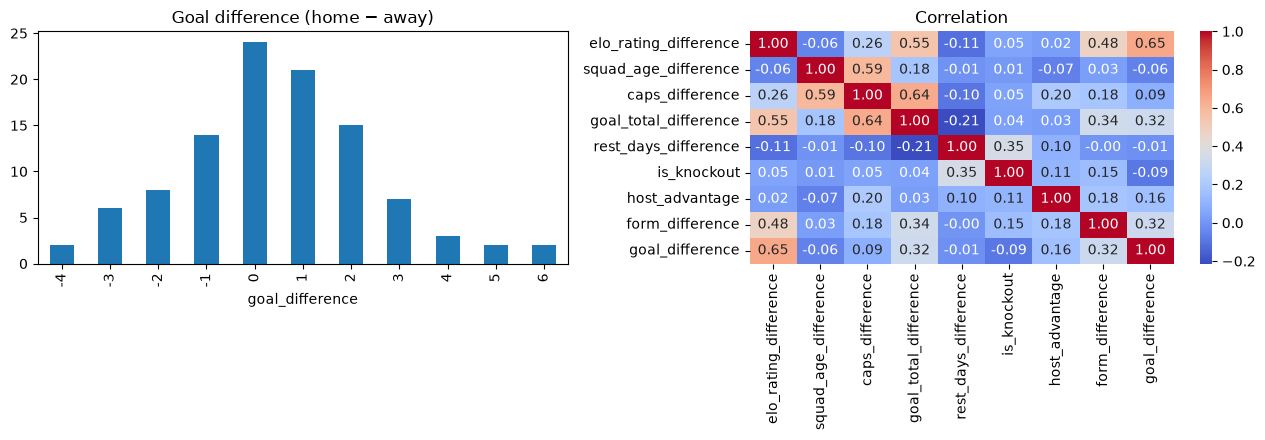

In [12]:
# distribution of goal difference, and correlation between all variables
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lr1["goal_difference"].value_counts().sort_index().plot(kind="bar", ax=ax[0])
ax[0].set_title("Goal difference (home − away)")
sns.heatmap(lr1[features1 + ["goal_difference"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation")
plt.tight_layout()
plt.show()

### Train and evaluate

In [13]:
# separate the features from the target
X1 = lr1[features1]
y1 = lr1["goal_difference"]

# keep 20% of the matches aside to test the model on unseen data
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=PERMA_SEED)

# train the model and predict the test matches
model1 = LinearRegression()
model1.fit(X1_train, y1_train)
y1_pred = model1.predict(X1_test)

# effect of each feature
pd.Series(model1.coef_, index=features1).round(4)

elo_rating_difference    0.0064
squad_age_difference     0.0846
caps_difference         -0.0013
goal_total_difference    0.0011
rest_days_difference     0.1795
is_knockout             -0.7783
host_advantage           1.1681
form_difference         -0.0202
dtype: float64

In [14]:
# error scores and R-squared to measure prediction quality
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse / (y_true.max() - y_true.min())
    r2 = r2_score(y_true, y_pred)
    print(f"MAE: {mae:.3f}  MSE: {mse:.3f}  RMSE: {rmse:.3f}  NRMSE: {nrmse:.3f}  R2: {r2:.3f}")

# baseline: always predict the average goal difference from the training data
baseline1 = np.full(len(y1_test), y1_train.mean())

print("Baseline:")
evaluate(y1_test, baseline1)
print("Linear regression:")
evaluate(y1_test, y1_pred)

Baseline:
MAE: 1.782  MSE: 5.147  RMSE: 2.269  NRMSE: 0.252  R2: -0.017
Linear regression:
MAE: 1.471  MSE: 3.109  RMSE: 1.763  NRMSE: 0.196  R2: 0.386


In [15]:
# OLS summary for p-values and adjusted R-squared
ols1 = sm.OLS(y1_train, sm.add_constant(X1_train)).fit()
print(ols1.summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.519
Model:                            OLS   Adj. R-squared:                  0.467
Method:                 Least Squares   F-statistic:                     9.981
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.58e-09
Time:                        16:38:45   Log-Likelihood:                -142.65
No. Observations:                  83   AIC:                             303.3
Df Residuals:                      74   BIC:                             325.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.24

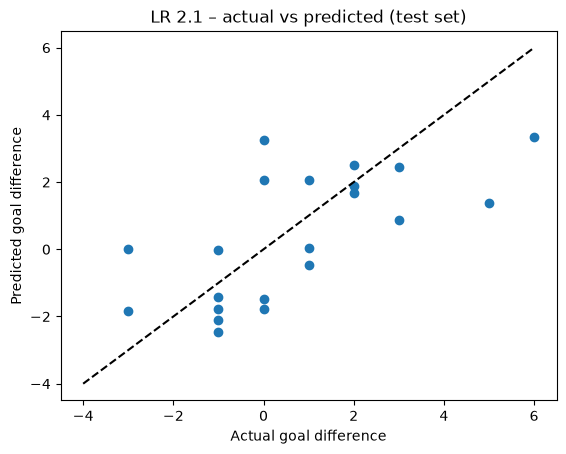

In [16]:
# compare actual and predicted goal differences on the test set
plt.scatter(y1_test, y1_pred)
plt.plot([-4, 6], [-4, 6], "k--")
plt.xlabel("Actual goal difference")
plt.ylabel("Predicted goal difference")
plt.title("LR 2.1 – actual vs predicted (test set)")
plt.show()

## Part 3 – LR 2.2: Predicting goals scored by a team
One row per team per match (208 rows). Target = goals scored by that team.

| Feature | Meaning | Related to LR 2.1? |
|---|---|---|
| elo_rating | Team's pre-tournament Elo | yes (Elo) |
| opp_elo_rating | Opponent's pre-tournament Elo | yes (Elo) |
| prev_xg_for | Team's average xG in earlier matches | yes (form) |
| fwd_goals | Team's forwards' international goals | yes (career goals) |
| avg_height | Team's average height | no |
| opp_avg_height | Opponent's average height | no |
| ref_cards | Referee's average cards per game (referees are appointed before the match) | no |
| elevation_km | Stadium altitude in km | no |


In [17]:
# add the opponent's Elo and height to each row
opp = team_matches[["match_id", "team_id", "elo_rating", "avg_height"]].rename(
    columns={"team_id": "opp_id", "elo_rating": "opp_elo_rating", "avg_height": "opp_avg_height"})

lr2 = team_matches.merge(opp, on=["match_id", "opp_id"])
lr2["elevation_km"] = lr2["elevation"] / 1000

# referee's average cards per game for each match
refs = pd.read_sql("SELECT m.match_id, r.avg_cards_per_game AS ref_cards "
                   "FROM matches m JOIN referees r ON r.referee_id = m.referee_id", conn)
lr2 = lr2.merge(refs, on="match_id")

features2 = ["elo_rating", "opp_elo_rating", "prev_xg_for", "fwd_goals",
             "avg_height", "opp_avg_height", "ref_cards", "elevation_km"]

lr2 = lr2[["match_id", "team_id", "opp_id"] + features2 + ["goals_for"]].sort_values(["match_id", "team_id"])

print(lr2.shape)
print("Missing values:", lr2.isna().sum().sum())
lr2.head()

(208, 12)
Missing values: 0


,match_id,team_id,opp_id,elo_rating,opp_elo_rating,prev_xg_for,fwd_goals,avg_height,opp_avg_height,ref_cards,elevation_km,goals_for
0,1,1,2,1810,1620,1.3,75,179.500000,178.846154,4.8,2.200,2
5,1,2,1,1620,1810,1.3,33,178.846154,179.500000,4.8,2.200,0
9,2,3,4,1800,1740,1.3,75,181.923077,185.730769,4.0,1.566,2
12,2,4,3,1740,1800,1.3,53,185.730769,181.923077,4.0,1.566,1
15,3,5,6,1795,1645,1.3,87,182.307692,187.076923,3.7,0.076,1
